In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Localiza a raiz a partir da pasta do notebook, da raiz do repositório ou de src/.
caminho_atual = Path.cwd().resolve()
raiz = next(( pasta for pasta in (caminho_atual, *caminho_atual.parents) if (pasta / "resultados" / "tabelas" / "e1_frequencias.csv").is_file()), None,)

if raiz is None:
    raise FileNotFoundError(
        "Não encontrei resultados/tabelas/e1_frequencias.csv. "
        "Salve o notebook em notebooks/ dentro do repositório e gere os CSVs antes de executá-lo."
        )

arquivo_frequencias = raiz / "resultados" / "tabelas" / "e1_frequencias.csv"
arquivo_resumo = raiz / "resultados" / "tabelas" / "e1_metricas_resumo.csv"
pasta_graficos = raiz / "resultados" / "graficos" / "notebooks"
pasta_graficos.mkdir(parents=True, exist_ok=True)

print("Raiz do projeto:", raiz)
print("Frequências:", arquivo_frequencias)
print("Resumo:", arquivo_resumo)
print("Gráficos serão salvos em:", pasta_graficos)

Raiz do projeto: /home/joaovictor/maquina-estatistica
Frequências: /home/joaovictor/maquina-estatistica/resultados/tabelas/e1_frequencias.csv
Resumo: /home/joaovictor/maquina-estatistica/resultados/tabelas/e1_metricas_resumo.csv
Gráficos serão salvos em: /home/joaovictor/maquina-estatistica/resultados/graficos/notebooks


In [3]:
df = pd.read_csv(arquivo_frequencias)
df_resumo = pd.read_csv(arquivo_resumo)

print("Tabela de frequências e probabilidades:")
display(df)

print("Métricas exportadas pelo programa:")
display(df_resumo)

Tabela de frequências e probabilidades:


,lucro_x,premio_p,combinacao,prob_teorica,contagem,freq_relativa,diferenca_abs
0,-1,0.0,Outras (120 triplas),0.960,9588,0.9588,0.0012
1,4,5.0,A-A-A (+4),0.008,77,0.0077,0.0003
2,9,10.0,B-B-B (+9),0.008,88,0.0088,0.0008
3,14,15.0,C-C-C (+14),0.008,78,0.0078,0.0002
4,24,25.0,D-D-D (+24),0.008,88,0.0088,0.0008
5,49,50.0,E-E-E (+49),0.008,81,0.0081,0.0001


Métricas exportadas pelo programa:


,metrica,valor
0,Total de rodadas (N),10000
1,Semente utilizada,2026
2,Soma das contagens,10000
3,Soma das frequências relativas,1.000000
4,Lucro médio observado (créditos),-0.131500
5,Lucro médio teórico E[X] (créditos),-0.160000
6,RTP observado (%),86.85%
7,RTP teórico (%),84.00%
8,Proporção premiada observada,4.12%
9,Probabilidade teórica de prêmio,4.00%


In [4]:
# Verificamos os resultados a partir das categorias e contagens, sem sortear novamente.
colunas_obrigatorias = {
    "lucro_x", "premio_p", "combinacao", "prob_teorica", "contagem", "freq_relativa"
}
assert colunas_obrigatorias.issubset(df.columns), "Colunas esperadas não encontradas no CSV."

n = int(df["contagem"].sum())
assert n == 10_000, f"E1 deveria conter 10.000 rodadas, mas contém {n}."
assert len(df) == 6, "São esperadas seis categorias de resultado."
assert set(df["lucro_x"].astype(int)) == {-1, 4, 9, 14, 24, 49}
assert np.isclose(df["prob_teorica"].sum(), 1.0)
assert np.isclose(df["freq_relativa"].sum(), 1.0)
assert np.allclose(df["freq_relativa"], df["contagem"] / n)
assert np.allclose(df["lucro_x"], df["premio_p"] - 1)

# Médias ponderadas pelas frequências absolutas de cada categoria.
lucro_medio_obs = np.average(df["lucro_x"], weights=df["contagem"])
premio_medio_obs = np.average(df["premio_p"], weights=df["contagem"])
rtp_obs = 100 * premio_medio_obs  # aposta fixa de 1 crédito
freq_premiada_obs = df.loc[df["premio_p"] > 0, "contagem"].sum() / n

# Desvio-padrão AMOSTRAL: divisor N-1 (não N).
soma_quadrados = (df["contagem"] * (df["lucro_x"] - lucro_medio_obs) ** 2).sum()
desvio_padrao_amostral = np.sqrt(soma_quadrados / (n - 1))

# Parâmetros teóricos calculados a partir da tabela.
premio_medio_teo = (df["premio_p"] * df["prob_teorica"]).sum()
lucro_medio_teo = (df["lucro_x"] * df["prob_teorica"]).sum()
rtp_teo = 100 * premio_medio_teo
freq_premiada_teo = df.loc[df["premio_p"] > 0, "prob_teorica"].sum()

assert np.isclose(premio_medio_teo, 0.84)
assert np.isclose(lucro_medio_teo, -0.16)
assert np.isclose(rtp_teo, 84.0)
assert np.isclose(freq_premiada_teo, 0.04)

# Conferência adicional com as métricas exportadas no segundo CSV.
metricas_csv = df_resumo.set_index("metrica")["valor"]

def valor_numerico(metrica):
    return float(str(metricas_csv.loc[metrica]).strip().replace("%", ""))

assert np.isclose(lucro_medio_obs, valor_numerico("Lucro médio observado (créditos)"), atol=1e-6)
assert np.isclose(rtp_obs, valor_numerico("RTP observado (%)"), atol=0.005)
assert np.isclose(desvio_padrao_amostral,
                  valor_numerico("Desvio-padrão amostral s (divisor N-1)"), atol=1e-5)

print("Conferências concluídas: contagens, probabilidades, lucro, RTP e desvio-padrão.")

Conferências concluídas: contagens, probabilidades, lucro, RTP e desvio-padrão.


In [5]:
comparacao = df[["combinacao", "lucro_x", "contagem"]].copy()
comparacao["Probabilidade teórica (%)"] = df["prob_teorica"] * 100
comparacao["Frequência observada (%)"] = df["freq_relativa"] * 100
comparacao["Diferença (p.p.)"] = (
    comparacao["Frequência observada (%)"] - comparacao["Probabilidade teórica (%)"]
)

resumo_indicadores = pd.DataFrame({
    "Indicador": [
        "Probabilidade de prêmio (%)", "Prêmio médio (créditos)",
        "Lucro líquido médio (créditos)", "RTP (%)"
    ],
    "Teórico": [freq_premiada_teo * 100, premio_medio_teo, lucro_medio_teo, rtp_teo],
    "Observado": [freq_premiada_obs * 100, premio_medio_obs, lucro_medio_obs, rtp_obs],
})

print("Categorias do Experimento 1:")
display(comparacao.round(4))
print("Principais indicadores:")
display(resumo_indicadores.round(4))
print(f"Desvio-padrão amostral do lucro: {desvio_padrao_amostral:.4f} créditos")

Categorias do Experimento 1:


,combinacao,lucro_x,contagem,Probabilidade teórica (%),Frequência observada (%),Diferença (p.p.)
0,Outras (120 triplas),-1,9588,96.0,95.88,-0.12
1,A-A-A (+4),4,77,0.8,0.77,-0.03
2,B-B-B (+9),9,88,0.8,0.88,0.08
3,C-C-C (+14),14,78,0.8,0.78,-0.02
4,D-D-D (+24),24,88,0.8,0.88,0.08
5,E-E-E (+49),49,81,0.8,0.81,0.01


Principais indicadores:


,Indicador,Teórico,Observado
0,Probabilidade de prêmio (%),4.00,4.1200
1,Prêmio médio (créditos),0.84,0.8685
2,Lucro líquido médio (créditos),-0.16,-0.1315
3,RTP (%),84.00,86.8500


Desvio-padrão amostral do lucro: 5.2750 créditos


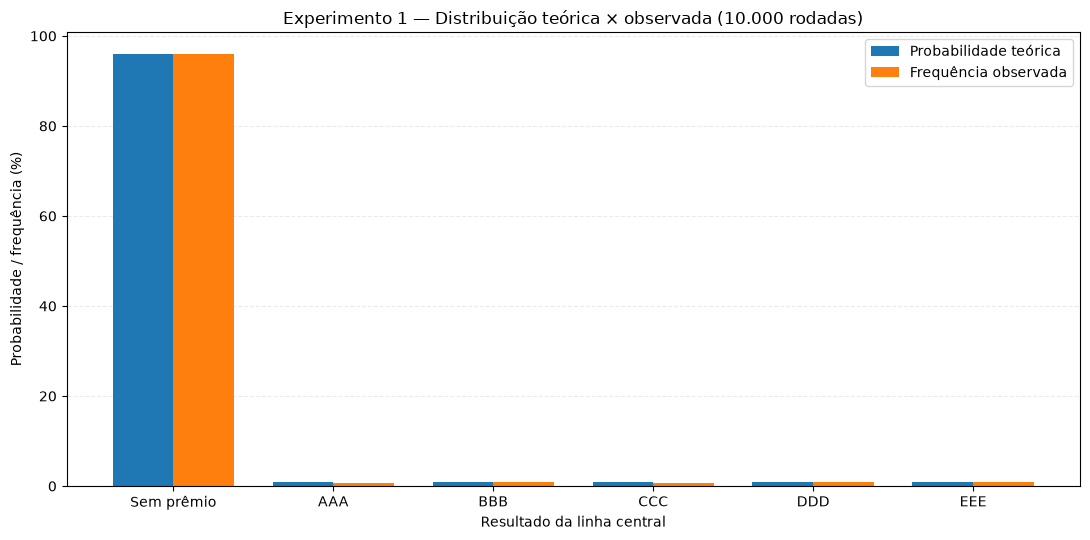

In [6]:
rotulos = ["Sem prêmio", "AAA", "BBB", "CCC", "DDD", "EEE"]
indices = np.arange(len(df))
largura = 0.38

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(indices - largura / 2, df["prob_teorica"] * 100,
       largura, label="Probabilidade teórica")
ax.bar(indices + largura / 2, df["freq_relativa"] * 100,
       largura, label="Frequência observada")

ax.set_xticks(indices, rotulos)
ax.set_ylabel("Probabilidade / frequência (%)")
ax.set_xlabel("Resultado da linha central")
ax.set_title("Experimento 1 — Distribuição teórica × observada (10.000 rodadas)")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(pasta_graficos / "e1_frequencias_todas_categorias.png", dpi=200, bbox_inches="tight")
plt.show()

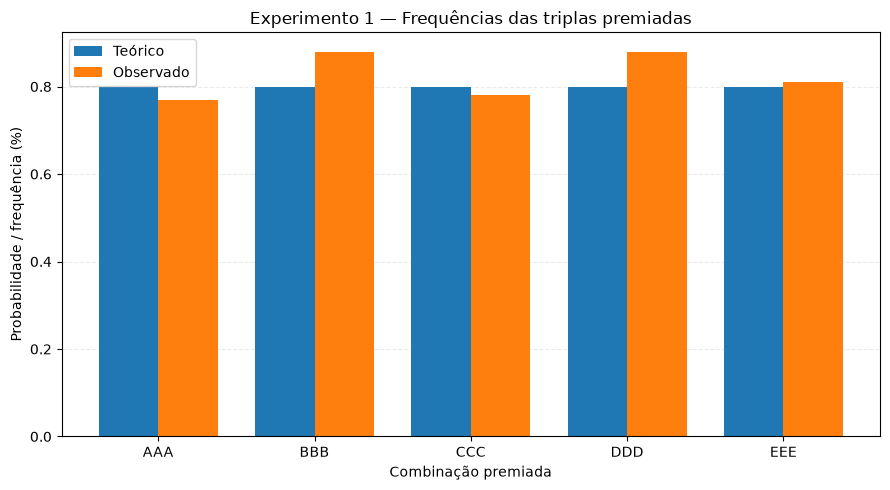

In [7]:
premiadas = df.loc[df["premio_p"] > 0].copy()
rotulos_premiadas = [c.split(" ")[0].replace("-", "") for c in premiadas["combinacao"]]
indices = np.arange(len(premiadas))

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(indices - largura / 2, premiadas["prob_teorica"] * 100,
       largura, label="Teórico")
ax.bar(indices + largura / 2, premiadas["freq_relativa"] * 100,
       largura, label="Observado")
ax.set_xticks(indices, rotulos_premiadas)
ax.set_xlabel("Combinação premiada")
ax.set_ylabel("Probabilidade / frequência (%)")
ax.set_title("Experimento 1 — Frequências das triplas premiadas")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(pasta_graficos / "e1_frequencias_premiadas.png", dpi=200, bbox_inches="tight")
plt.show()

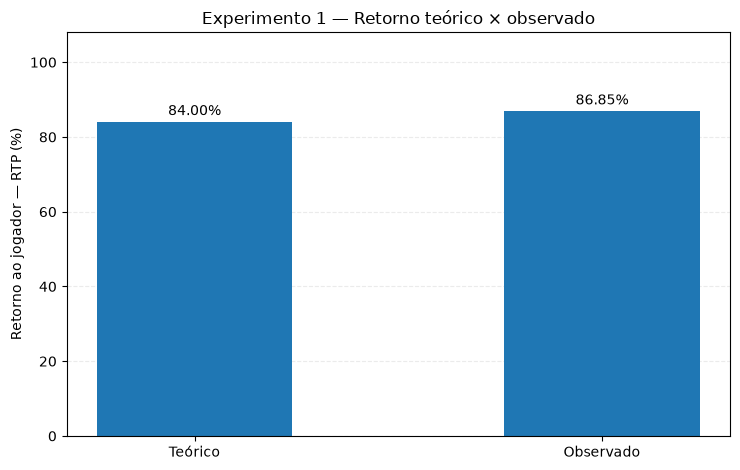

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
barras = ax.bar(["Teórico", "Observado"], [rtp_teo, rtp_obs], width=0.48)

for barra in barras:
    altura = barra.get_height()
    ax.annotate(f"{altura:.2f}%", (barra.get_x() + barra.get_width() / 2, altura),
                xytext=(0, 5), textcoords="offset points", ha="center")

ax.set_ylabel("Retorno ao jogador — RTP (%)")
ax.set_ylim(0, max(100, rtp_teo, rtp_obs) * 1.08)
ax.set_title("Experimento 1 — Retorno teórico × observado")
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(pasta_graficos / "e1_rtp_teorico_observado.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
print(f"Foram analisadas {n:,} rodadas com semente 2026.".replace(",", "."))
print(f"Chance de prêmio: teoria {freq_premiada_teo * 100:.2f}% | observação {freq_premiada_obs * 100:.2f}%")
print(f"RTP: teoria {rtp_teo:.2f}% | observação {rtp_obs:.2f}%")
print(f"Lucro médio líquido: teoria {lucro_medio_teo:.4f} | observação {lucro_medio_obs:.4f} créditos")
print(f"Desvio-padrão amostral do lucro: {desvio_padrao_amostral:.4f} créditos")
print(f"Gráficos salvos em: {pasta_graficos}")

Foram analisadas 10.000 rodadas com semente 2026.
Chance de prêmio: teoria 4.00% | observação 4.12%
RTP: teoria 84.00% | observação 86.85%
Lucro médio líquido: teoria -0.1600 | observação -0.1315 créditos
Desvio-padrão amostral do lucro: 5.2750 créditos
Gráficos salvos em: /home/joaovictor/maquina-estatistica/resultados/graficos/notebooks
